# BAN 612 Data Analytics
## Final Project

- Hong Ngoc Dinh
- Nora Cook
- Hmwe Pyant Thin Chit
## AI-assisted Analytics: The Good and Bad


# Part A - Initial Data Audit

First we checked the dataset before using AI.


In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from textwrap import dedent
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

In [57]:
# Load dataset
df_raw = pd.read_csv('Project_Data.csv')
df = df_raw.copy()

## Explore Dataset

In [58]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2205 entries, 0 to 2204
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          2205 non-null   object 
 1   customer_id       2205 non-null   object 
 2   order_date        2205 non-null   object 
 3   channel           2205 non-null   object 
 4   product_category  2205 non-null   object 
 5   customer_type     2205 non-null   object 
 6   order_value       2205 non-null   float64
 7   discount_pct      2205 non-null   float64
 8   promised_days     2205 non-null   int64  
 9   actual_days       2205 non-null   int64  
 10  shipping_cost     2205 non-null   float64
 11  customer_rating   2205 non-null   int64  
 12  returned          2205 non-null   int64  
dtypes: float64(3), int64(4), object(6)
memory usage: 224.1+ KB


,order_id,customer_id,order_date,channel,product_category,customer_type,order_value,discount_pct,promised_days,actual_days,shipping_cost,customer_rating,returned
0,O00001,AC0429,2025-11-28,Store,Grocery,Consumer,61.21,0.20,3,3,18.76,5,1
1,O00002,AC0416,2025-12-02,Store,Apparel,Business,42.36,0.05,3,4,16.12,5,0
2,O00003,AC0695,2026-03-07,Store,Grocery,Consumer,79.18,0.05,7,7,25.93,5,1
3,O00004,AC0315,2026-03-23,Online,Electronics,Consumer,86.67,0.15,3,3,22.11,4,0
4,O00005,AC0365,2026-04-02,Store,Apparel,Consumer,33.56,0.00,7,9,30.72,3,1


Obversaton from Inspecting:
- 2,205 rows and 13 columns
- `order_date` is object and should be datetime
- Dataset has order, customer, shipping, rating and return information

## Missing Values and Duplicates

In [59]:
print("Missing values before cleaning:")
print(df.isna().sum())

print("\nExact duplicate rows:", df.duplicated().sum())
print("Duplicate order_id values:", df["order_id"].duplicated().sum())

Missing values before cleaning:
order_id            0
customer_id         0
order_date          0
channel             0
product_category    0
customer_type       0
order_value         0
discount_pct        0
promised_days       0
actual_days         0
shipping_cost       0
customer_rating     0
returned            0
dtype: int64

Exact duplicate rows: 5
Duplicate order_id values: 5


Obversaton from Inspecting:
- No missing values at first
- 5 exact duplicate rows
- These duplicates also make duplicate `order_id`

## Check Category Values

In [60]:
for col in ['channel', 'product_category', 'customer_type', 'promised_days', 'actual_days', 'customer_rating', 'returned']:
    print(df[col].value_counts(), end='\n\n')

channel
Online    1330
Store      875
Name: count, dtype: int64

product_category
Electronics    821
Apparel        510
Home           487
Grocery        387
Name: count, dtype: int64

customer_type
Consumer      1684
Business       413
Enterprise     108
Name: count, dtype: int64

promised_days
2    565
3    558
5    542
7    540
Name: count, dtype: int64

actual_days
5     367
3     324
7     302
2     282
4     279
6     253
8     200
1      67
10     66
9      65
Name: count, dtype: int64

customer_rating
4      941
5      654
3      493
2      101
1        9
999      7
Name: count, dtype: int64

returned
0    1887
1     318
Name: count, dtype: int64



Obversaton from Inspecting:
- `customer_rating` has a strange value 999
- `returned` only has 0 and 1
- Other category values look consistent

## Check Numeric Values

In [61]:
df.describe()

,order_value,discount_pct,promised_days,actual_days,shipping_cost,customer_rating,returned
count,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000
mean,135.893814,0.181043,4.214966,5.002721,25.584172,7.127891,0.144218
std,521.459439,0.868643,1.919206,2.247804,32.034697,55.993882,0.351390
min,6.870000,0.000000,2.000000,1.000000,-1.210000,1.000000,0.000000
25%,42.360000,0.050000,2.000000,3.000000,17.230000,3.000000,0.000000
50%,68.910000,0.150000,3.000000,5.000000,22.600000,4.000000,0.000000
75%,117.410000,0.200000,5.000000,7.000000,28.870000,5.000000,0.000000
max,15000.000000,25.000000,7.000000,10.000000,912.500000,999.000000,1.000000


In [62]:
# Look at values that seem unusual
print("Discount values greater than 1:")
print(df.loc[df["discount_pct"] > 1, ["order_id", "discount_pct"]])

print("\nNegative shipping cost:")
print(df.loc[df["shipping_cost"] < 0, ["order_id", "shipping_cost"]])

print("\nRating = 999:")
print(df.loc[df["customer_rating"] == 999, ["order_id", "customer_rating"]])

Discount values greater than 1:
     order_id  discount_pct
77     O00078          20.0
477    O00478          20.0
877    O00878          15.0
1677   O01678          25.0
2077   O02078           5.0

Negative shipping cost:
     order_id  shipping_cost
1420   O01421          -1.21

Rating = 999:
     order_id  customer_rating
50     O00051              999
350    O00351              999
650    O00651              999
950    O00951              999
1250   O01251              999
1550   O01551              999
1850   O01851              999


## More Data Quality Problems Found
- 7 rows have `customer_rating = 999`
- 5 `discount_pct` values are 5, 15, 20 or 25 instead of decimal format
- 1 `shipping_cost` is negative
- Some Enterprise `order_value` are very high, but they may be real business orders so we did not remove them

## Check Date

In [63]:
# Use mixed format because the file contains more than one date format
parsed_dates = pd.to_datetime(df["order_date"], format="mixed", errors="coerce")
print("Dates that cannot be converted:", parsed_dates.isna().sum())
df.loc[parsed_dates.isna(), ["order_id", "order_date"]]

Dates that cannot be converted: 1


,order_id,order_date
333,O00334,2025-13-05


## Obversaton:
- One date is `2025-13-05` and cannot be converted correctly
- We do not know the correct date, so we did not guess it

## Questions to Investigate
1. What are the customer ratings?
2. How many orders are returned?
3. Which product categories have higher return rates?
4. Is there a difference between promised days and actual days?

# Part B - Use AI

## Prompt 1 - Understand the Dataset

**Prompt:** Help me understand the dataset.

**AI response:** Gemini said the dataset has 2,205 rows and 13 columns and explained what the columns mean. It also pointed out that `order_date` should be converted to date format.

In [64]:
# Gemini generate explanation

# Here is a comprehensive breakdown of your dataset based on the completed session history:
print("--- Dataset Specifications ---")
print("Total Rows: 2,205")
print("Total Columns: 13")

# Recreate a sample of the structural overview matching your exact data
columns_info = {
    'order_id': "Unique identifier for each order (Object)",
    'customer_id': "Unique identifier for each customer (Object)",
    'order_date': "Date the order was placed (Datetime)",
    'channel': "Sales channel: Store, Online (Object)",
    'product_category': "Categories: Grocery, Apparel, Electronics, Home (Object)",
    'customer_type': "Customer Segment: Consumer, Business, Enterprise (Object)",
    'order_value': "Value of the placed order (Float64)",
    'discount_pct': "Discount percentage applied (Float64)",
    'promised_days': "Expected delivery timeframe: 2, 3, 5, 7 days (Int64)",
    'actual_days': "Actual days taken to deliver (ranging from 1 to 10 days) (Int64)",
    'shipping_cost': "Associated shipping cost (Float64)",
    'customer_rating': "Customer satisfaction rating: 1 to 5 (Float64, with '999' successfully handled as NaN)",
    'returned': "Product return status: 1 for Yes, 0 for No (Int64)"
}

print("\n--- Key Column Meanings and Data Types ---")
for col, desc in columns_info.items():
    print(f" - {col:18} : {desc}")

print("\n--- Key Insights from Your Notebook's Analysis ---")
print("1. Return Rate: Out of 2,205 orders, 318 products were returned (approx. 14.4% return rate).")
print("2. Rating Cleanliness: Ratings contain values from 1 to 5. An anomaly value '999' was successfully removed and replaced with NaN.")
print("3. Delivery Speed: Orders usually take between 1 to 10 days to arrive. Comparing actual versus promised delivery shows that many orders arrive exactly on time or up to 3 days late, though some arrive 1 day early.")

--- Dataset Specifications ---
Total Rows: 2,205
Total Columns: 13

--- Key Column Meanings and Data Types ---
 - order_id           : Unique identifier for each order (Object)
 - customer_id        : Unique identifier for each customer (Object)
 - order_date         : Date the order was placed (Datetime)
 - channel            : Sales channel: Store, Online (Object)
 - product_category   : Categories: Grocery, Apparel, Electronics, Home (Object)
 - customer_type      : Customer Segment: Consumer, Business, Enterprise (Object)
 - order_value        : Value of the placed order (Float64)
 - discount_pct       : Discount percentage applied (Float64)
 - promised_days      : Expected delivery timeframe: 2, 3, 5, 7 days (Int64)
 - actual_days        : Actual days taken to deliver (ranging from 1 to 10 days) (Int64)
 - shipping_cost      : Associated shipping cost (Float64)
 - customer_rating    : Customer satisfaction rating: 1 to 5 (Float64, with '999' successfully handled as NaN)
 - returne

## Prompt 2 - Cleaning Steps

**Prompt:** Suggest cleaning steps for this dataset.

**AI response:** Gemini suggested converting `order_date`, replacing rating 999 with missing, checking duplicates, checking numeric ranges and looking for unusual values.

In [65]:
try:
    # 1. Reload the dataset if it's uploaded
    df_ai = pd.read_csv("Project_Data.csv")
    print("✔ Successfully loaded Project_Data.csv")

    # 2. Convert datetime with proper parsing
    df_ai["order_date"] = pd.to_datetime(df_ai["order_date"], format='mixed', errors='coerce')
    print("✔ Standardized 'order_date' column to datetime format.")

    # 3. Handle anomalies in customer ratings (replacing 999 with NaN)
    initial_nulls = df_ai["customer_rating"].isnull().sum()
    df_ai["customer_rating"] = df_ai["customer_rating"].replace(999, np.nan)
    final_nulls = df_ai["customer_rating"].isnull().sum()
    print(f"✔ Cleaned 'customer_rating' (converted {final_nulls - initial_nulls} anomaly values [999] to NaN).")

    # 4. Strip whitespace from string/categorical columns to prevent mismatch issues
    string_cols = ['channel', 'product_category', 'customer_type']
    for col in string_cols:
        df_ai[col] = df_ai[col].astype(str).str.strip()
    print("✔ Trimmed whitespace from categorical columns.")

    # 5. Check and drop duplicate rows
    duplicates_count = df_ai.duplicated().sum()
    if duplicates_count > 0:
        df_ai = df_ai.drop_duplicates()
        print(f"✔ Removed {duplicates_count} duplicated rows.")
    else:
        print("✔ Verified: No duplicated rows found.")

    # Display current missing values in the cleaned dataset
    print("\n--- Cleaned Dataset Null Value Summary ---")
    print(df_ai.isnull().sum())

except FileNotFoundError:
    print("⚠️ 'Project_Data.csv' was not found in the environment.")

✔ Successfully loaded Project_Data.csv
✔ Standardized 'order_date' column to datetime format.
✔ Cleaned 'customer_rating' (converted 7 anomaly values [999] to NaN).
✔ Trimmed whitespace from categorical columns.
✔ Removed 5 duplicated rows.

--- Cleaned Dataset Null Value Summary ---
order_id            0
customer_id         0
order_date          1
channel             0
product_category    0
customer_type       0
order_value         0
discount_pct        0
promised_days       0
actual_days         0
shipping_cost       0
customer_rating     7
returned            0
dtype: int64


## Prompt 3 - Python Code

**Prompt:** Generate or improve the Python code.

**AI response:** Gemini generated code to upload and clean the dataset. Some AI-generated code did not run because Gemini did not use the correct file path when we worked on Google Collaboration.

The code below was edited to make it run.

In [66]:
# 2. Standardize order_date
df_ai["order_date"] = pd.to_datetime(df_ai["order_date"], format='mixed', errors='coerce')
print("✔ Standardized 'order_date' column to datetime format.")

# 3. Replace 999 anomaly ratings with NaN
initial_nulls = df_ai["customer_rating"].isnull().sum()
df_ai["customer_rating"] = df_ai["customer_rating"].replace(999, np.nan)
final_nulls = df_ai["customer_rating"].isnull().sum()
print(f"✔ Cleaned 'customer_rating' (converted {final_nulls - initial_nulls} anomaly values [999] to NaN).")

# 4. Trim whitespaces
string_cols = ['channel', 'product_category', 'customer_type']
for col in string_cols:
    df_ai[col] = df_ai[col].astype(str).str.strip()
print("✔ Trimmed whitespace from categorical columns.")

# 5. Drop duplicate rows
duplicates_count = df_ai.duplicated().sum()
if duplicates_count > 0:
    df_ai = df_ai.drop_duplicates()
    print(f"✔ Removed {duplicates_count} duplicated rows.")
else:
    print("✔ Verified: No duplicated rows found.")

# Display first few rows and null status
print("\n--- Cleaned Dataset Null Value Summary ---")
display(df_ai.isnull().sum().to_frame(name='Missing Values'))
print("\n--- Cleaned Dataset Sample ---")
display(df_ai.head())

✔ Standardized 'order_date' column to datetime format.
✔ Cleaned 'customer_rating' (converted 0 anomaly values [999] to NaN).
✔ Trimmed whitespace from categorical columns.
✔ Verified: No duplicated rows found.

--- Cleaned Dataset Null Value Summary ---


,Missing Values
order_id,0
customer_id,0
order_date,1
channel,0
product_category,0
customer_type,0
order_value,0
discount_pct,0
promised_days,0
actual_days,0



--- Cleaned Dataset Sample ---


,order_id,customer_id,order_date,channel,product_category,customer_type,order_value,discount_pct,promised_days,actual_days,shipping_cost,customer_rating,returned
0,O00001,AC0429,2025-11-28,Store,Grocery,Consumer,61.21,0.20,3,3,18.76,5.0,1
1,O00002,AC0416,2025-12-02,Store,Apparel,Business,42.36,0.05,3,4,16.12,5.0,0
2,O00003,AC0695,2026-03-07,Store,Grocery,Consumer,79.18,0.05,7,7,25.93,5.0,1
3,O00004,AC0315,2026-03-23,Online,Electronics,Consumer,86.67,0.15,3,3,22.11,4.0,0
4,O00005,AC0365,2026-04-02,Store,Apparel,Consumer,33.56,0.00,7,9,30.72,3.0,1


## Prompt 4 - Exploratory Analysis and Visualizations

**Prompt:** Suggest exploratory analyses and generate visualizations.

**AI response:** Gemini suggested checking:
- delivery delay vs customer rating
- return rate by product category
- return rate by channel
- correlations between numeric variables


=== ANALYSIS 1: Does Delivery Delay Hurt Customer Ratings? ===


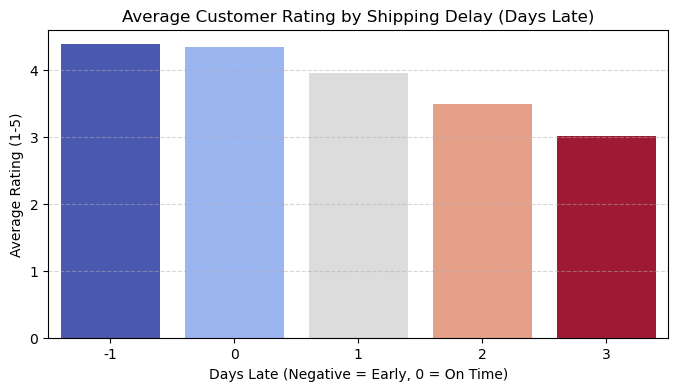

,delay_days,customer_rating
0,-1,4.386973
1,0,4.344086
2,1,3.963563
3,2,3.498382
4,3,3.017123



=== ANALYSIS 2: Where are Returns Happening Most? ===


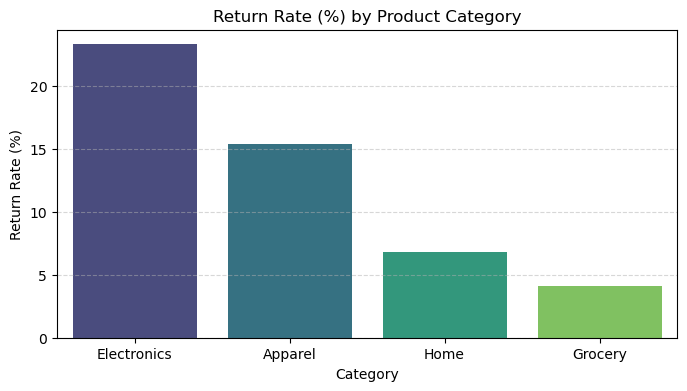

,product_category,return_rate_pct
0,Apparel,15.354331
1,Electronics,23.292683
2,Grocery,4.145078
3,Home,6.790123



=== ANALYSIS 3: Financial Profiles & Cost Correlation ===


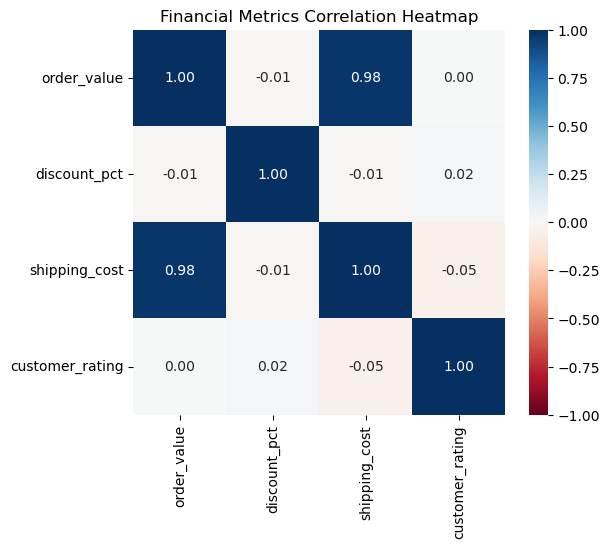

In [67]:
# Get the dataset and make a copy for analysis
analysis_df = df_ai.copy()

# Ensure minimal standardizations
if 'customer_rating' in analysis_df.columns:
    analysis_df['customer_rating'] = analysis_df['customer_rating'].replace(999, np.nan)
if 'order_date' in analysis_df.columns:
    analysis_df['order_date'] = pd.to_datetime(analysis_df['order_date'], errors='coerce')
if 'actual_days' in analysis_df.columns and 'promised_days' in analysis_df.columns:
    analysis_df['delay_days'] = analysis_df['actual_days'] - analysis_df['promised_days']

# -------------------------------------------------------------
# ANALYSIS 1: The Impact of Shipping Delays on Customer Satisfaction
# -------------------------------------------------------------
print("\n=== ANALYSIS 1: Does Delivery Delay Hurt Customer Ratings? ===")
if 'delay_days' in analysis_df.columns and 'customer_rating' in analysis_df.columns:
    delay_satisfaction = analysis_df.groupby('delay_days')['customer_rating'].mean().reset_index()

    plt.figure(figsize=(8, 4))
    sns.barplot(data=delay_satisfaction, x='delay_days', y='customer_rating', palette='coolwarm', hue='delay_days', legend=False)
    plt.title('Average Customer Rating by Shipping Delay (Days Late)')
    plt.xlabel('Days Late (Negative = Early, 0 = On Time)')
    plt.ylabel('Average Rating (1-5)')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.show()

    # Print numeric insights
    display(delay_satisfaction)

# -------------------------------------------------------------
# ANALYSIS 2: Return Rates across Channels and Product Categories
# -------------------------------------------------------------
print("\n=== ANALYSIS 2: Where are Returns Happening Most? ===")
if 'returned' in analysis_df.columns and 'product_category' in analysis_df.columns:
    return_by_cat = analysis_df.groupby('product_category')['returned'].mean().reset_index()
    return_by_cat['return_rate_pct'] = return_by_cat['returned'] * 100

    plt.figure(figsize=(8, 4))
    sns.barplot(data=return_by_cat.sort_values(by='return_rate_pct', ascending=False), x='product_category', y='return_rate_pct', palette='viridis', hue='product_category')
    plt.title('Return Rate (%) by Product Category')
    plt.xlabel('Category')
    plt.ylabel('Return Rate (%)')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.show()

    display(return_by_cat[['product_category', 'return_rate_pct']])

# -------------------------------------------------------------
# ANALYSIS 3: Financial Correlation (Order Value, Discounts, and Shipping Costs)
# -------------------------------------------------------------
print("\n=== ANALYSIS 3: Financial Profiles & Cost Correlation ===")
financial_cols = ['order_value', 'discount_pct', 'shipping_cost', 'customer_rating']
available_fin_cols = [c for c in financial_cols if c in analysis_df.columns]

if len(available_fin_cols) > 1:
    corr_matrix = analysis_df[available_fin_cols].corr()

    plt.figure(figsize=(6, 5))
    sns.heatmap(corr_matrix, annot=True, cmap='RdBu', vmin=-1, vmax=1, fmt='.2f')
    plt.title('Financial Metrics Correlation Heatmap')
    plt.show()

## Prompt 5 - Interpret Results

**Prompt:** Interpret the selected results.

**AI response:** 
1. Delivery Delays and Customer Satisfaction: Average customer ratings decrease as delivery delays increase, suggesting that timely delivery is important for customer satisfaction.
2. Product Return Rates: The category chart identifies which product categories have the highest return rates, helping prioritize potential quality, product-description, or shipping issues.
3. Financial and Rating Relationships: The correlation heatmap helps examine relationships among discounts, shipping costs, order values, and customer ratings, showing which variables may be associated with one another.

# Part C - Verify the AI
We checked the AI claims again using Python and the real dataset.

In [68]:
# Make a copy for verification
verify_df = pd.read_csv("Project_Data.csv")

# Basic checks used for several AI claims
print("Shape:", verify_df.shape)
print("Returned orders:", verify_df["returned"].sum())
print("Raw return rate (%):", round(verify_df["returned"].mean() * 100, 2))
print("Number of rating 999 values:", (verify_df["customer_rating"] == 999).sum())
print("Actual delivery day range:", verify_df["actual_days"].min(), "to", verify_df["actual_days"].max())

verify_df["delay_days"] = verify_df["actual_days"] - verify_df["promised_days"]
print("Delay values:", sorted(verify_df["delay_days"].unique()))

Shape: (2205, 13)
Returned orders: 318
Raw return rate (%): 14.42
Number of rating 999 values: 7
Actual delivery day range: 1 to 10
Delay values: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [69]:
# Verify the AI claim that delay is related to lower ratings
rating_check = verify_df.copy()
rating_check["customer_rating"] = rating_check["customer_rating"].replace(999, np.nan)
rating_by_delay = rating_check.groupby("delay_days")["customer_rating"].agg(["count", "mean"])
rating_by_delay

,count,mean
delay_days,,
-1,261,4.386973
0,841,4.347206
1,495,3.961616
2,309,3.498382
3,292,3.017123


In [70]:
return_by_cat = verify_df.groupby('product_category')['returned'].mean().reset_index()
return_by_cat['return_rate_pct'] = return_by_cat['returned'] * 100
return_by_cat

,product_category,returned,return_rate_pct
0,Apparel,0.152941,15.294118
1,Electronics,0.232643,23.264312
2,Grocery,0.041344,4.134367
3,Home,0.067762,6.776181


In [71]:
mask_discount_test = verify_df["discount_pct"] > 1
verify_df.loc[mask_discount_test, "discount_pct"] = verify_df.loc[mask_discount_test, "discount_pct"] / 100
corr_matrix_test = verify_df[['order_value', 'discount_pct', 'shipping_cost', 'customer_rating']].corr()
corr_matrix_test

,order_value,discount_pct,shipping_cost,customer_rating
order_value,1.000000,-0.019956,0.976229,-0.002418
discount_pct,-0.019956,1.000000,-0.018975,0.033660
shipping_cost,0.976229,-0.018975,1.000000,-0.003522
customer_rating,-0.002418,0.033660,-0.003522,1.000000


## Verification Table

| AI claim/recommendation | How I checked it | Correct? | Action |
|---|---|---|---|
| Dataset has 2,205 rows and 13 columns. | `df.shape` | Yes | Keep |
| There are 5 duplicate rows. | `df.duplicated().sum()` | Yes | Remove duplicates |
| Rating 999 is invalid. | Checked rating values | Yes | Change 999 to missing |
| Delivery delay is related to lower ratings. | Grouped rating by `delay_days` | Yes | Keep finding |
| Electronics has a high return rate. | Grouped returns by product category | Yes | Keep finding |
| Correlation between `discount_pct` and  `'order_value`, `discount_pct`, `shipping_cost`, `customer_rating`| Correct the values in `discount_pct` | No | Keep finding |


# Part D - Find a Failure

**1. What AI suggested**

Gemini suggested the return rate by channel, and correlations between numeric variables.

**2. Why it was a problem**

It mentioned the return rate by channel, but then not generate any visualization. The correlations between numeric variables use the `discount_pct` but it didn't check or know that there are some values is suspicious.

**3. How we found the problem**

We checked the code and output and saw that Gemini didn't generate the return rate by channel graph while mentioning it in the answer and the code. For the `discount_pct`, we have observed in part A.

**4. What we did instead**

We cleaned and checked the results again with Python before using the findings.

# Part E - End-to-End Analysis

## Clean Dataset


In [72]:
# Start again from the original file so the cleaning steps are easy to follow
clean_df = pd.read_csv("Project_Data.csv")

# Remove exact duplicate rows
clean_df = clean_df.drop_duplicates().copy()

# Convert date. One impossible date will become NaT instead of guessing it.
clean_df["order_date"] = pd.to_datetime(clean_df["order_date"], format="mixed", errors="coerce")

# Rating should be 1 to 5
clean_df["customer_rating"] = clean_df["customer_rating"].replace(999, np.nan)

# Most discounts are stored as decimals. Convert the 5/15/20/25 entries to decimal form.
mask_discount = clean_df["discount_pct"] > 1
clean_df.loc[mask_discount, "discount_pct"] = clean_df.loc[mask_discount, "discount_pct"] / 100

# Negative shipping cost does not make business sense, but the correct value is unknown.
clean_df.loc[clean_df["shipping_cost"] < 0, "shipping_cost"] = np.nan

# Add a useful delivery variable
clean_df["delay_days"] = clean_df["actual_days"] - clean_df["promised_days"]
clean_df["delivery_status"] = np.select(
    [clean_df["delay_days"] < 0, clean_df["delay_days"] == 0, clean_df["delay_days"] > 0],
    ["Early", "On time", "Late"],
    default="Unknown"
)

print("Cleaned shape:", clean_df.shape)
print("\nMissing values after cleaning:")
print(clean_df.isna().sum())

Cleaned shape: (2200, 15)

Missing values after cleaning:
order_id            0
customer_id         0
order_date          1
channel             0
product_category    0
customer_type       0
order_value         0
discount_pct        0
promised_days       0
actual_days         0
shipping_cost       1
customer_rating     7
returned            0
delay_days          0
delivery_status     0
dtype: int64


Cleaning Notes:
- Removed 5 exact duplicate rows
- Changed 7 invalid ratings (999) to missing
- Converted 5 discount values to decimal format
- Changed 1 negative shipping cost to missing
- Changed the invalid date to missing because the correct date is unknown

## Finding 1 - Delivery Delays and Customer Ratings

In [73]:
delay_summary = clean_df.groupby("delay_days").agg(
    orders=("order_id", "size"),
    average_rating=("customer_rating", "mean")
).reset_index()

delay_summary["average_rating"] = delay_summary["average_rating"].round(2)
delay_summary

,delay_days,orders,average_rating
0,-1,261,4.39
1,0,839,4.34
2,1,497,3.96
3,2,309,3.50
4,3,294,3.02


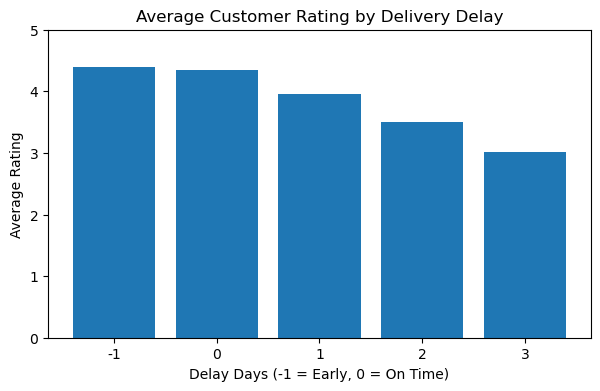

In [74]:
plt.figure(figsize=(7, 4))
plt.bar(delay_summary["delay_days"].astype(str), delay_summary["average_rating"])
plt.title("Average Customer Rating by Delivery Delay")
plt.xlabel("Delay Days (-1 = Early, 0 = On Time)")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.show()

Obversation:
- Average rating goes down when the delay gets longer
- Early orders average about 4.39
- On-time orders average about 4.34
- Orders 3 days late average about 3.02
- About 50% of cleaned orders are late

Manager Note:
Delivery time looks important for customer satisfaction. The company should pay attention to late orders.


## Finding 2 - Return Rate by Product Category

In [75]:
category_returns = clean_df.groupby("product_category").agg(
    orders=("order_id", "size"),
    returns=("returned", "sum"),
    return_rate=("returned", "mean")
).reset_index()
category_returns["return_rate_pct"] = (category_returns["return_rate"] * 100).round(2)
category_returns.sort_values("return_rate_pct", ascending=False)

,product_category,orders,returns,return_rate,return_rate_pct
1,Electronics,820,191,0.232927,23.29
0,Apparel,508,78,0.153543,15.35
3,Home,486,33,0.067901,6.79
2,Grocery,386,16,0.041451,4.15


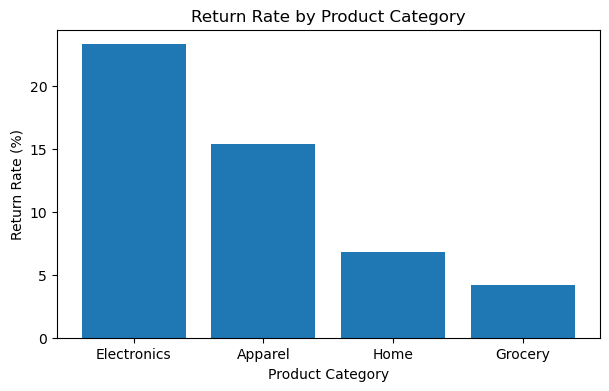

In [76]:
plot_cat = category_returns.sort_values("return_rate_pct", ascending=False)
plt.figure(figsize=(7, 4))
plt.bar(plot_cat["product_category"], plot_cat["return_rate_pct"])
plt.title("Return Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Return Rate (%)")
plt.show()

Obversaton:
- Electronics has the highest return rate: about 23.29%
- Apparel: about 15.35%
- Grocery has the lowest: about 4.15%

Manager Note:
Electronics returns are much higher. The company should check product quality, descriptions and reasons for return.


## Finding 3 - Online vs. Store Return Rate

In [77]:
channel_returns = clean_df.groupby("channel").agg(
    orders=("order_id", "size"),
    returns=("returned", "sum"),
    return_rate=("returned", "mean")
).reset_index()
channel_returns["return_rate_pct"] = (channel_returns["return_rate"] * 100).round(2)
channel_returns

,channel,orders,returns,return_rate,return_rate_pct
0,Online,1327,207,0.155991,15.60
1,Store,873,111,0.127148,12.71


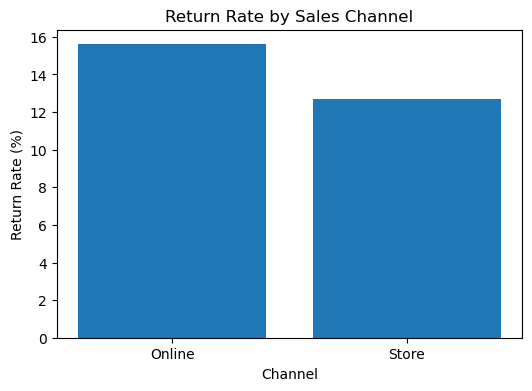

In [78]:
plt.figure(figsize=(6, 4))
plt.bar(channel_returns["channel"], channel_returns["return_rate_pct"])
plt.title("Return Rate by Sales Channel")
plt.xlabel("Channel")
plt.ylabel("Return Rate (%)")
plt.show()

Obversaton:
- Online return rate: about 15.60%
- Store return rate: about 12.71%

Manager Note:
Online returns are a little higher. The company can review online product information and whether customers have enough information before buying.


## Finding 4 - Returned Orders and Customer Ratings

In [79]:
return_rating = clean_df.groupby("returned").agg(
    orders=("order_id", "size"),
    average_rating=("customer_rating", "mean"),
    average_order_value=("order_value", "mean")
).reset_index()
return_rating["average_rating"] = return_rating["average_rating"].round(2)
return_rating["average_order_value"] = return_rating["average_order_value"].round(2)
return_rating

,returned,orders,average_rating,average_order_value
0,0,1882,4.11,139.94
1,1,318,3.14,105.07


Obversaton:
- Non-returned orders average about 4.11 rating
- Returned orders average about 3.14
- Overall return rate is about 14.45%

Manager Note:
Returned orders also have lower ratings. We do not have return reasons in this dataset, so we cannot say exactly why customers returned the products.


## Final Summary

In [80]:
print("Final rows:", len(clean_df))
print("Overall return rate (%):", round(clean_df["returned"].mean() * 100, 2))
print("Late orders (%):", round((clean_df["delay_days"] > 0).mean() * 100, 2))
print("Average valid rating:", round(clean_df["customer_rating"].mean(), 2))

# Save the cleaned dataset used for the final analysis
clean_df.to_csv("Project_Data_cleaned.csv", index=False)

Final rows: 2200
Overall return rate (%): 14.45
Late orders (%): 50.0
Average valid rating: 3.97


## Work Done Independently and With AI

**Independent / checked with Python**
- Initial data check
- Data cleaning decisions
- Part C verification
- Final calculations and graphs
- Final interpretation after checking results

**AI-assisted**
- Ideas for cleaning
- Ideas for analyses
- Starter Python code
- Suggested visualizations

**AI suggestion rejected / not trusted directly**
- Gemini interpreted results without knowing the error values in `discount_pct`, and skip some part while mentioning in the answer.

# Final Reflection

**1. Where did AI save you the most time?**

AI helped us get ideas for what to analyze and gave starter code. This saved time because we did not need to start everything from zero.

**2. Where was human judgment most important?**

Human judgment was most important during cleaning and checking AI results. For example, we did not want to guess the invalid date or automatically remove very high Enterprise orders.

**3. Which AI output was most misleading?**

The most misleading part was when Gemini don't really know the different in units of measure can affect the values.

**4. Did AI identify anything important that you initially missed?**

Yes. AI gave useful ideas to compare delivery delay with rating and to compare return rates across categories. We still checked the results ourselves.

**5. When would you not give AI-generated analysis directly to a manager?**

We would not give it directly if we did not check the dataset, code and output first, especially when the result could affect an important business decision.

**6. Did this assignment change how much you trust AI analysis?**

Yes. AI is useful for ideas and code, but we trust it less if we cannot verify the output. We learned that we still need to check the data and results ourselves.
